In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (111, 60)
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.69   1.82  ...    8.03    7.94    8.11    8.26    8.15    8.07    7.35   
3  70.25  73.22  ...   93.59   92.69   92.62   92.97   96.37   95.68   88.64   
4  79.41  83.16  ...  116.04  115.10  115.07  115.76  119.25  118.40  109.75   

     2021    2

In [ ]:
# Remove rows without a country name
df = df.dropna(subset=["Country"]).copy()

# Convert yearly columns into individual rows
data = df.melt(
    id_vars=["Country"],
    var_name="year",
    value_name="energy_consumption"
)

# Select India only
data = data[data["Country"].str.strip() == "India"].copy()

# Convert columns to numeric
data["year"] = pd.to_numeric(data["year"], errors="coerce")
data["energy_consumption"] = pd.to_numeric(
    data["energy_consumption"], errors="coerce"
)

# Handle missing values
data = data.dropna(
    subset=["year", "energy_consumption"]
)

# Sort chronologically
data["year"] = data["year"].astype(int)
data = data.sort_values("year").reset_index(drop=True)

print(data.head())
print(data.tail())
print("Total records:", len(data))
print("Missing values:\n", data.isnull().sum().sum())

  Country  year  energy_consumption
0   India  1965                2.23
1   India  1966                2.30
2   India  1967                2.37
3   India  1968                2.53
4   India  1969                2.81
   Country  year  energy_consumption
54   India  2019               33.54
55   India  2020               31.78
56   India  2021               34.51
57   India  2022               36.37
58   India  2023               39.02
Total records: 59
Missing values:
 0


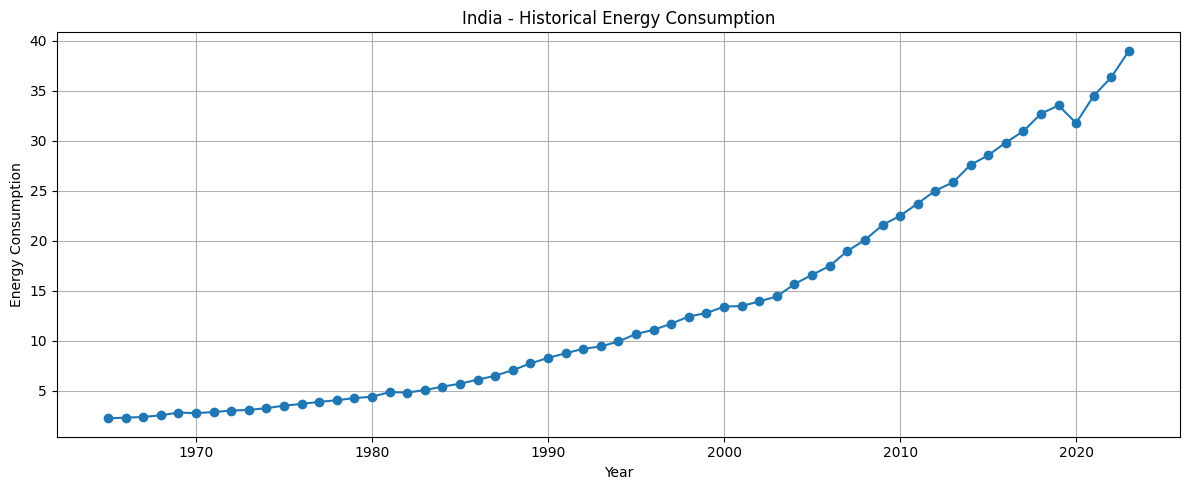

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    data["year"],
    data["energy_consumption"],
    marker="o"
)

plt.title("India - Historical Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

values = data[["energy_consumption"]].to_numpy(dtype=float)

# First 80% of years for training; final 20% for testing
split_index = int(len(values) * 0.8)

scaler = MinMaxScaler()

# Fit only on the training period
scaler.fit(values[:split_index])

scaled_values = scaler.transform(values)

print("Original values:")
print(values[:5])

print("Normalized values:")
print(scaled_values[:5])

print("Training cutoff year:", data["year"].iloc[split_index - 1])
print("First test year:", data["year"].iloc[split_index])

Original values:
[[2.23]
 [2.3 ]
 [2.37]
 [2.53]
 [2.81]]
Normalized values:
[[0.        ]
 [0.00325581]
 [0.00651163]
 [0.01395349]
 [0.02697674]]
Training cutoff year: 2011
First test year: 2012


In [ ]:
window_size = 5

X = []
y = []
target_indices = []

for i in range(window_size, len(scaled_values)):
    X.append(scaled_values[i-window_size:i])
    y.append(scaled_values[i, 0])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



X_train shape: (42, 5, 1)
X_test shape: (12, 5, 1)
Training samples: 42
Testing samples: 12


In [ ]:

model = Sequential([
    Input(shape=(window_size, 1)),
    LSTM(16),
    Dense(8, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,297 (5.07 KB)

 Trainable params: 1,297 (5.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=200,
    batch_size=4,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0284 - val_loss: 0.2138
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0104 - val_loss: 0.1197
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0054 - val_loss: 0.0659
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0063 - val_loss: 0.0434
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0065 - val_loss: 0.0374
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0052 - val_loss: 0.0361
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0038 - val_loss: 0.0328
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0028 - val_loss: 0.0264
Epoch 9/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0020 - val_loss: 0.0194
Epoch 10/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0015 - val_loss: 0.0141
Epoch 11/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0012 - val_loss: 0.0107
Epoch 12/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 8.7152e-04 - va

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions and actual values back to original units
y_pred = scaler.inverse_transform(pred_scaled).ravel()
y_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

test_years = data["year"].to_numpy()[target_indices[test_mask]]

results = pd.DataFrame({
    "Year": test_years,
    "Actual": y_actual,
    "Predicted": y_pred
})

print(results.round(2).to_string(index=False))

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"\nMAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

 Year  Actual  Predicted
 2012   25.02  23.309999
 2013   25.84  24.430000
 2014   27.59  25.440001
 2015   28.55  26.490000
 2016   29.83  27.469999
 2017   30.96  28.440001
 2018   32.72  29.340000
 2019   33.54  30.350000
 2020   31.78  31.160000
 2021   34.51  31.480000
 2022   36.37  32.189999
 2023   39.02  32.910000

MAE: 2.7269
RMSE: 3.0505


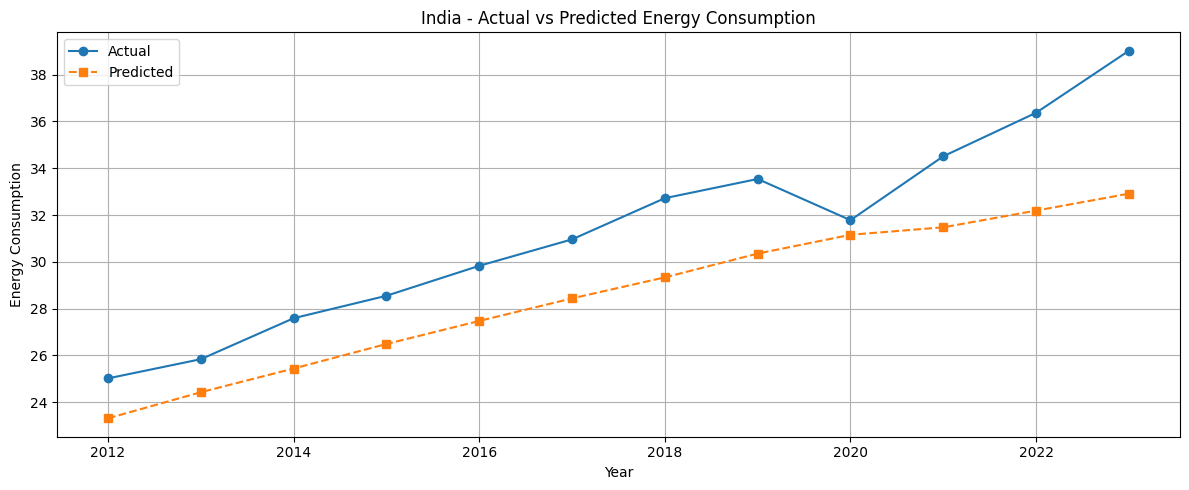

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_years,
    y_actual,
    marker="o",
    label="Actual"
)

plt.plot(
    test_years,
    y_pred,
    marker="s",
    linestyle="--",
    label="Predicted"
)

plt.title("India - Actual vs Predicted Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()